# Widmo Fouriera - przykładowe pola

Klatki zredukowane (`_zdf`) z `processed-ofp/science/`. Wszystkie pola naraz: w każdym wierszu obraz i obok jego widmo mocy.
Podstawy (co znaczą częstości, kropki, prążki): `fft_basics.ipynb`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

# przykładowe pola: (teleskop, klatka, opis)
FIELDS = [
    ("zb08", "zb08c_1345_53721", "RR Cet, V 0.5 s - rzadkie pole, krótka ekspozycja"),
    ("zb08", "zb08c_1345_82947", "OGLE-LMC-ECL-37120, g 300 s - LMC, gęste pole"),
    ("jk15", "jk15c_1344_76356", "NGC1851, r 25 s - gromada kulista"),
    ("jk15", "jk15c_1345_70689", "NGC253-NW, g 200 s - duża galaktyka"),
    ("wk06", "wk06c_1345_68684", "TPHE, V 18 s - pole standardów"),
    ("wk06", "wk06c_1345_80450", "OGLE-LMC-ECL-20299, u_s 300 s - LMC, ciemne niebo"),
]


## Obraz i widmo mocy

- Odejmujemy medianę (poziom tła), inaczej środek widma zdominuje średnia.
- Moc = |FFT|² / liczba pikseli [ADU²]; biały szum dałby wszędzie poziom = wariancja.
- Częstość w cyklach na piksel, od -0.5 do 0.5; okres w pikselach = 1 / częstość.

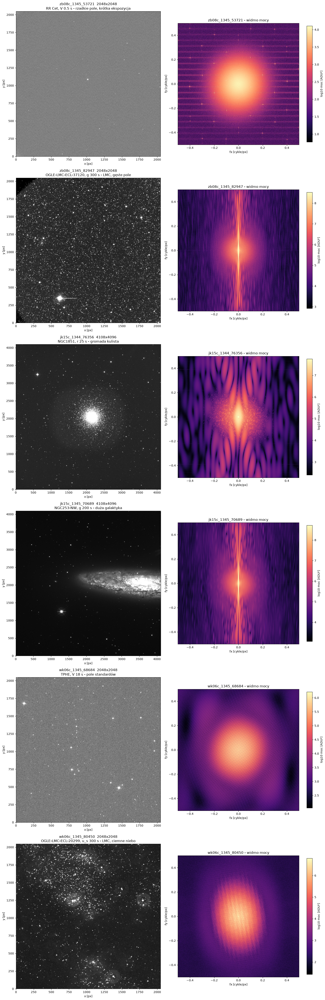

In [2]:
ZOOM = 0.5   # pokazywany zakres częstości [cykle/px]; 0.5 = całe widmo, np. 0.05 = tylko okresy > 20 px

fig, axes = plt.subplots(len(FIELDS), 2, figsize=(16, 8 * len(FIELDS)))
for (tel, frame, desc), (ax_im, ax_sp) in zip(FIELDS, axes):
    night = frame.split("_")[1]
    img = fits.getdata(f"/data/fits/{tel}/processed-ofp/science/{night}/{frame}/{frame}_zdf.fits").astype(np.float64)
    ny, nx = img.shape

    data = img - np.median(img)
    power = np.abs(np.fft.fftshift(np.fft.fft2(data)))**2 / (nx * ny)
    fx = np.fft.fftshift(np.fft.fftfreq(nx))
    fy = np.fft.fftshift(np.fft.fftfreq(ny))
    logp = np.log10(power + 1e-12)

    lo, hi = np.percentile(img, [1, 99])
    ax_im.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax_im.set_title(f"{frame}  {nx}x{ny}\n{desc}")
    ax_im.set_xlabel("x [px]")
    ax_im.set_ylabel("y [px]")

    lo, hi = np.percentile(logp, [5, 99.9])
    ims = ax_sp.imshow(logp, origin="lower", cmap="magma", vmin=lo, vmax=hi, extent=[fx[0], fx[-1], fy[0], fy[-1]])
    ax_sp.set_xlim(-ZOOM, ZOOM)
    ax_sp.set_ylim(-ZOOM, ZOOM)
    fig.colorbar(ims, ax=ax_sp, label="log10 moc [ADU²]", shrink=0.8)
    ax_sp.set_title(f"{frame} - widmo mocy")
    ax_sp.set_xlabel("fx [cykle/px]")
    ax_sp.set_ylabel("fy [cykle/px]")

    del img, data, power, logp   # klatki jk15 są duże (4k), zwalniamy pamięć przed następną
plt.tight_layout()
plt.show()


## Co widać

Bez okna i na pojedynczych klatkach, więc to obserwacje i podejrzenia, nie wnioski. Odwołania do przykładów z
`fft_basics.ipynb`.

**Wspólne dla wszystkich pól**
- Okrągła plama w środku to gwiazdy: widmo PSF (przykład „gwiazda”), pocięte plamkami, bo gwiazd jest wiele i leżą losowo
  („gwiazdy w losowych miejscach”). Im ostrzejsze gwiazdy, tym szersza plama.
- Poza plamą zostaje szum. Tam, gdzie gwiazd jest mało, a tło niskie (RR Cet, TPHE), szum stanowi dużą część widma.
- Klatka nie jest okresowa, a FFT tak ją traktuje: brzegi klatki dokładają krzyż wzdłuż osi fx = 0 i fy = 0.

**zb08 RR Cet (0.5 s)**
- Regularna siatka ostrych kropek na całym widmie i poziome pasy. Kropki w regularnej siatce = coś okresowego na obrazie
  (przykład „9 gwiazd w siatce”).
- Na obrazie to widać wprost (wycinek niżej): regularna siatka słabych jasnych punktów, odstęp ~10 px w x. Autokorelacja daje
  przesunięcia (10, 0), (16, 25), (26, 25) px.
- Na tak krótkiej ekspozycji tło ma ~4 ADU, więc ta siatka jest jedną z najsilniejszych struktur w klatce. Skąd jest
  (detektor? kalibracja w OFP?), jeszcze nie wiemy - do sprawdzenia na surowej klatce i na innych zb08.

**zb08 LMC (300 s), jk15 NGC253, jk15 NGC1851 - pionowa linia przez środek**
- Pionowa linia w widmie = coś poziomego na obrazie (przykład „pozioma linia”).
- Na wszystkich trzech jest nasycona gwiazda z poziomą smugą (zb08 LMC ~(600, 350), NGC253 ~(1300, 1250), NGC1851
  ~(600, 3250)). Do tego krzyż od brzegów klatki.
- NGC253: galaktyka jest wydłużona w poziomie, więc jej plama w widmie jest wydłużona w pionie (szeroki obiekt -> wąskie
  widmo w tym kierunku). Galaktyka jest też ucięta prawym brzegiem, co wzmacnia efekt brzegu.
- NGC1851: oprócz tego duże, owalne wzory na wysokich częstościach. Pochodzenie niejasne. Może to nasycone, płaskie
  rdzenie jasnych gwiazd (ostre krawędzie, jak obwarzanki), może krzyże od pająka lustra. Autokorelacja ma też pik w
  (67, -21) px - podejrzany o ghost albo przypadkową parę jasnych gwiazd, do sprawdzenia.

**wk06 TPHE (18 s)**
- Plama okrągła, ale na brzegach widma ciemne obszary: na wysokich częstościach w niektórych kierunkach mocy jest mniej
  niż dla białego szumu. Szum nie jest więc całkiem biały, piksele są trochę skorelowane. Skąd - nie wiemy (do porównania
  z surową klatką).

**wk06 LMC u_s (300 s)**
- Plama eliptyczna i pochylona: gwiazdy są lekko wydłużone, w kierunku prostopadłym do dłuższej osi plamy.
- Ukośne, regularne prążki na plamie. Przy losowych gwiazdach regularne prążki znaczą powtarzające się przesunięcie
  („gwiazdy + ghosty”). Autokorelacja ma pik w (29, 3) px. Na wycinkach przy jasnych gwiazdach podwójnych obrazów
  jednak nie widać, więc to na razie tylko trop. Na obrazie widać też okrągłe, rozmyte obwarzanki (np. ~(1300, 1250),
  ~(1400, 200)) - kandydaci na ghosty.

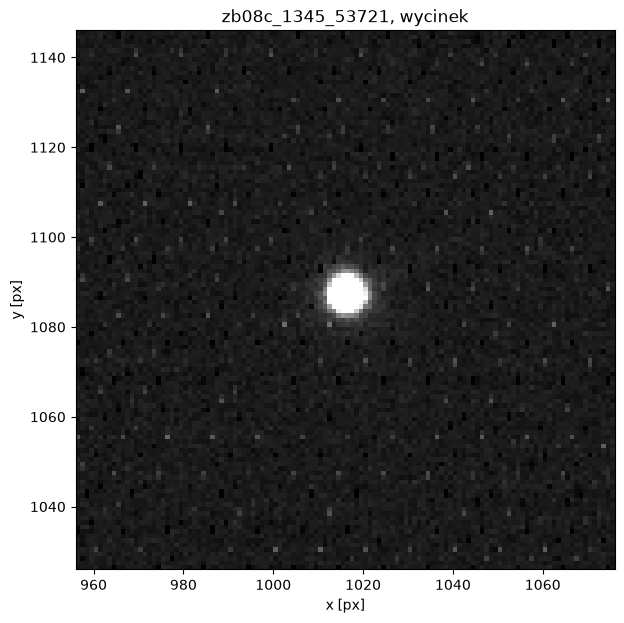

In [3]:
# zb08 RR Cet: wycinek wokół najjaśniejszej gwiazdy - siatka słabych jasnych punktów
img = fits.getdata("/data/fits/zb08/processed-ofp/science/1345/zb08c_1345_53721/zb08c_1345_53721_zdf.fits").astype(np.float64)
X0, Y0, HALF = 1016, 1086, 60   # środek i połowa rozmiaru wycinka [px]

plt.figure(figsize=(7, 7))
plt.imshow(img[Y0 - HALF:Y0 + HALF, X0 - HALF:X0 + HALF], origin="lower", cmap="gray", vmin=-30, vmax=300, extent=[X0 - HALF, X0 + HALF, Y0 - HALF, Y0 + HALF])
plt.title("zb08c_1345_53721, wycinek")
plt.xlabel("x [px]")
plt.ylabel("y [px]")
plt.show()
